Little (971827, 6) ..\EMG Recordings\little_finger_30mins_combined.csv
Middle (1086342, 6) ..\EMG Recordings\middle_finger_30mins_combined.csv
Ring (994165, 6) ..\EMG Recordings\ring_finger_30mins_combined.csv
Index (1015193, 6) ..\EMG Recordings\index_finger_30mins_combined.csv
Thumb (966764, 6) ..\EMG Recordings\thumb_finger_30mins_combined.csv

Combined files created:
Little -> ..\EMG Recordings\little_finger_30mins_combined.csv
Middle -> ..\EMG Recordings\middle_finger_30mins_combined.csv
Ring -> ..\EMG Recordings\ring_finger_30mins_combined.csv
Index -> ..\EMG Recordings\index_finger_30mins_combined.csv
Thumb -> ..\EMG Recordings\thumb_finger_30mins_combined.csv
Little windows: 1819
Middle windows: 1944
Ring windows: 1868
Index windows: 1870
Thumb windows: 1813

Dataset Information
Features: (9314, 20)
Labels: (9314,)
Features per window: 20

Finger Distribution
Middle    1944
Index     1870
Ring      1868
Little    1819
Thumb     1813
Name: count, dtype: int64

Session Distributi

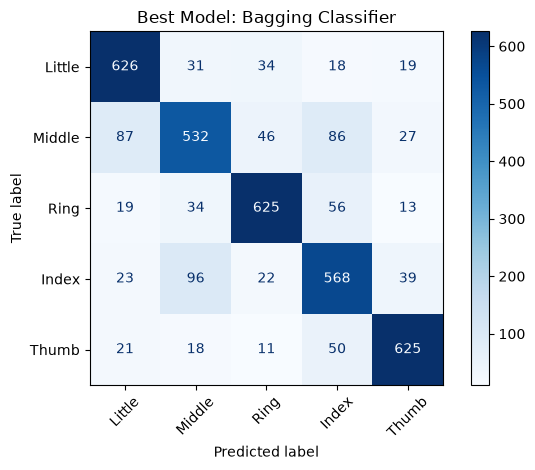

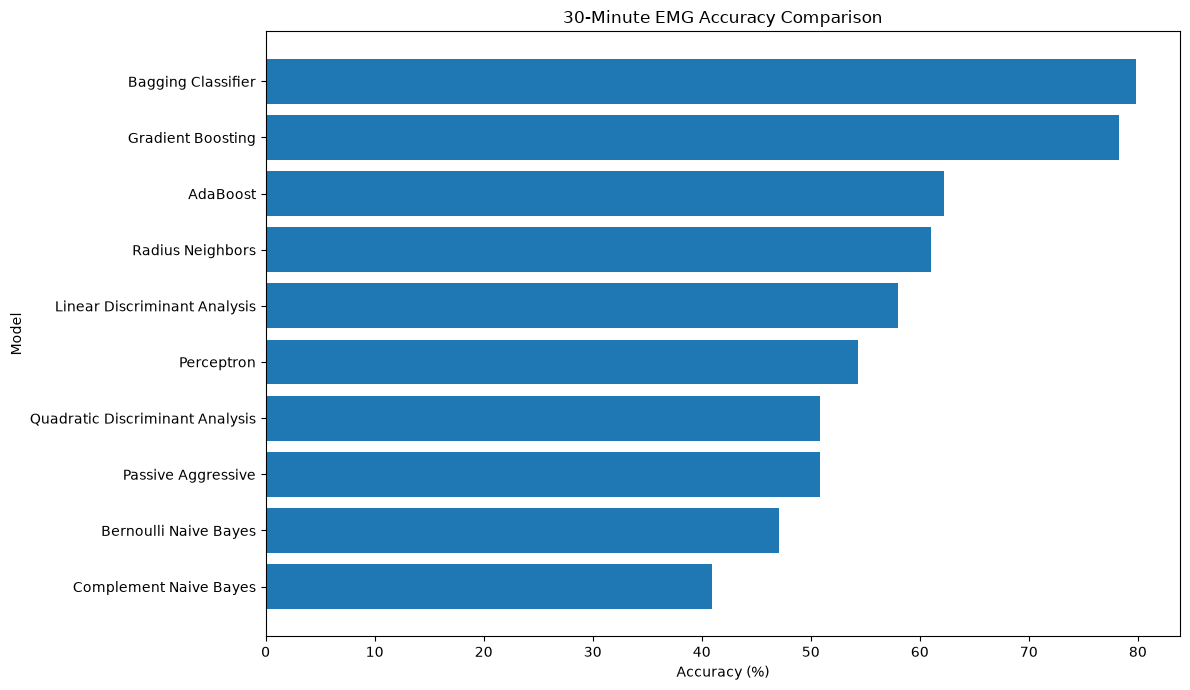

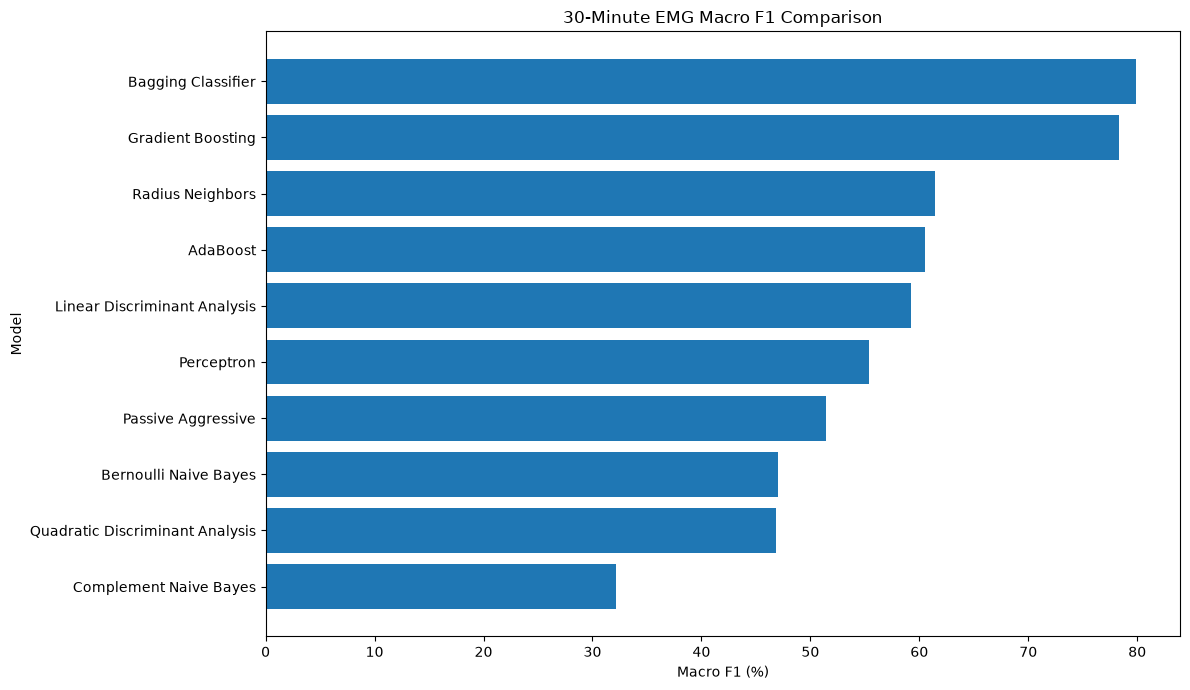

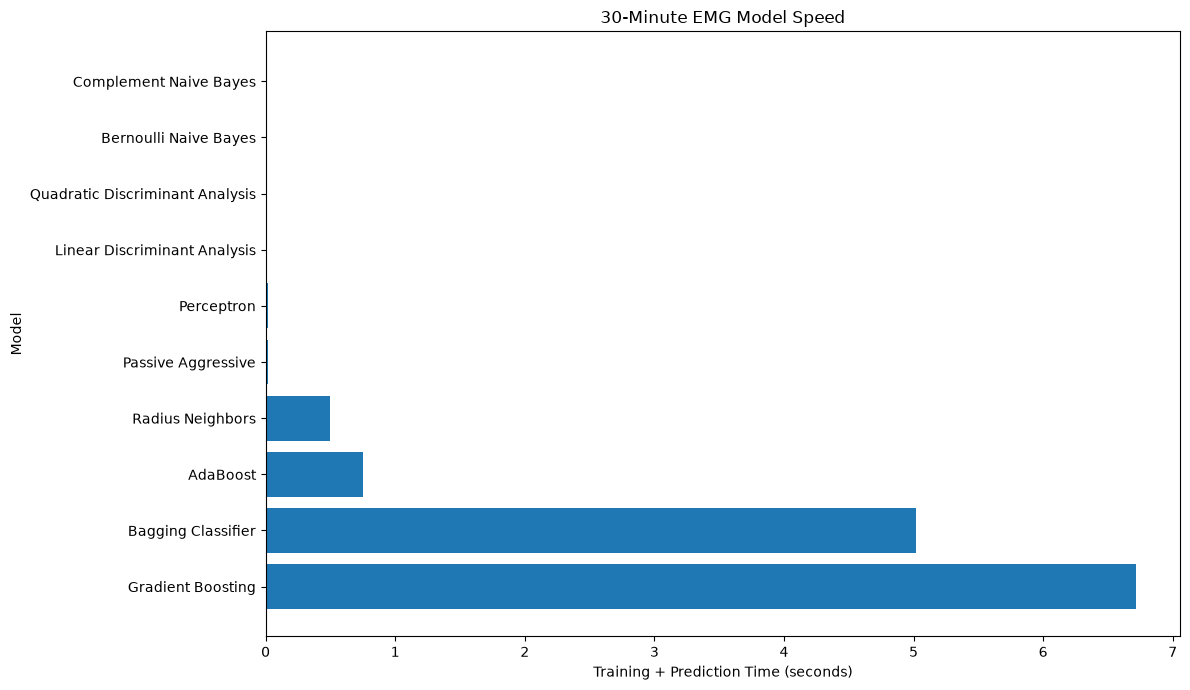


Accuracy and Speed Efficiency

                          Model  Accuracy  Macro F1  Training Time  Prediction Time  Total Time  Efficiency Score
         Complement Naive Bayes  0.409286  0.321589       0.002534         0.000455    0.002989        102.608831
          Bernoulli Naive Bayes  0.470746  0.470521       0.003519         0.000932    0.004451         86.364340
   Linear Discriminant Analysis  0.580247  0.592228       0.007392         0.000599    0.007991         64.535698
Quadratic Discriminant Analysis  0.508857  0.468794       0.005847         0.001646    0.007493         59.915539
                     Perceptron  0.543747  0.554005       0.014689         0.000577    0.015266         33.428007
             Passive Aggressive  0.508857  0.514140       0.019211         0.000590    0.019801         24.462617
               Radius Neighbors  0.610574  0.614597       0.004306         0.490427    0.494733          1.231659
                       AdaBoost  0.621846  0.604781     

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline

from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)

from sklearn.linear_model import (
    Perceptron,
    PassiveAggressiveClassifier
)

from sklearn.naive_bayes import (
    BernoulliNB,
    ComplementNB
)

from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    GradientBoostingClassifier
)

from sklearn.neighbors import RadiusNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

data_folder = Path("../EMG Recordings")

files = {
    "Little": {
        "5min": data_folder / "little finger emg_2sensor_20260922_123054.csv",
        "10min": data_folder / "little_finger 10mins.csv",
        "15min": data_folder / "little_finger_15mins.csv"
    },
    "Middle": {
        "5min": data_folder / "middle finger emg_2sensor_20260922_124337.csv",
        "10min": data_folder / "middle_finger_10mins.csv",
        "15min": data_folder / "middle_finger_15mins.csv"
    },
    "Ring": {
        "5min": data_folder / "Ring finger emg_2sensor_20260922_123712.csv",
        "10min": data_folder / "ring_finger_10mins.csv",
        "15min": data_folder / "ring_finger_15mins.csv"
    },
    "Index": {
        "5min": data_folder / "index emg_2sensor_20260922_124922.csv",
        "10min": data_folder / "index_finger_10mins.csv",
        "15min": data_folder / "index_finger_15mins.csv"
    },
    "Thumb": {
        "5min": data_folder / "Thumb finger emg_2sensor_20260922_125701.csv",
        "10min": data_folder / "thumb_finger_10mins.csv",
        "15min": data_folder / "thumb_finger_15mins.csv"
    }
}

combined_files = {}

for finger, session_files in files.items():

    combined_parts = []
    cumulative_time = 0.0

    for session_name in ["5min", "10min", "15min"]:

        data = pd.read_csv(
            session_files[session_name]
        )

        data = data[
            [
                "time_s",
                "emg1",
                "emg2"
            ]
        ].copy()

        data["time_s"] = pd.to_numeric(
            data["time_s"],
            errors="coerce"
        )

        data["emg1"] = pd.to_numeric(
            data["emg1"],
            errors="coerce"
        )

        data["emg2"] = pd.to_numeric(
            data["emg2"],
            errors="coerce"
        )

        data = data.dropna().reset_index(
            drop=True
        )

        data["session"] = session_name

        data["session_time_s"] = (
            data["time_s"]
            -
            data["time_s"].iloc[0]
        )

        if len(data) > 1:

            differences = np.diff(
                data["session_time_s"].values
            )

            positive_differences = differences[
                differences > 0
            ]

            if len(positive_differences) > 0:

                time_step = np.median(
                    positive_differences
                )

            else:

                time_step = 0.001

        else:

            time_step = 0.001

        data["combined_time_s"] = (
            data["session_time_s"]
            +
            cumulative_time
        )

        cumulative_time = (
            data["combined_time_s"].iloc[-1]
            +
            time_step
        )

        combined_parts.append(
            data
        )

    combined_data = pd.concat(
        combined_parts,
        ignore_index=True
    )

    output_file = (
        data_folder
        /
        f"{finger.lower()}_finger_30mins_combined.csv"
    )

    combined_data.to_csv(
        output_file,
        index=False
    )

    combined_files[
        finger
    ] = output_file

    print(
        finger,
        combined_data.shape,
        output_file
    )

print("\nCombined files created:")

for finger, file_path in combined_files.items():

    print(
        finger,
        "->",
        file_path
    )


def calculate_statistics(values):

    values = np.asarray(
        values,
        dtype=float
    )

    return [
        np.mean(values),
        np.median(values),
        np.min(values),
        np.max(values),
        np.std(values),
        np.var(values),
        np.max(values) - np.min(values),
        np.sqrt(
            np.mean(
                values ** 2
            )
        ),
        np.mean(
            np.abs(
                values
            )
        ),
        np.sum(
            np.abs(
                np.diff(
                    values
                )
            )
        )
    ]


statistic_names = [
    "Mean",
    "Median",
    "Minimum",
    "Maximum",
    "Standard_Deviation",
    "Variance",
    "Range",
    "RMS",
    "Mean_Absolute_Value",
    "Waveform_Length"
]

feature_names = []

for statistic in statistic_names:

    feature_names.append(
        f"EMG1_{statistic}"
    )

for statistic in statistic_names:

    feature_names.append(
        f"EMG2_{statistic}"
    )


def create_time_windows(
    data,
    window_seconds=1.0
):

    features = []
    sessions = []

    for session_name in [
        "5min",
        "10min",
        "15min"
    ]:

        session_data = data[
            data["session"]
            ==
            session_name
        ].copy()

        if len(session_data) == 0:

            continue

        session_data = session_data.sort_values(
            "session_time_s"
        )

        duration = session_data[
            "session_time_s"
        ].iloc[-1]

        number_of_windows = int(
            duration
            //
            window_seconds
        )

        for window_number in range(
            number_of_windows
        ):

            start_time = (
                window_number
                *
                window_seconds
            )

            end_time = (
                start_time
                +
                window_seconds
            )

            window = session_data[
                (
                    session_data["session_time_s"]
                    >=
                    start_time
                )
                &
                (
                    session_data["session_time_s"]
                    <
                    end_time
                )
            ]

            if len(window) < 2:

                continue

            emg1_statistics = calculate_statistics(
                window["emg1"].values
            )

            emg2_statistics = calculate_statistics(
                window["emg2"].values
            )

            window_features = np.concatenate(
                [
                    emg1_statistics,
                    emg2_statistics
                ]
            )

            features.append(
                window_features
            )

            sessions.append(
                session_name
            )

    return (
        np.array(features),
        np.array(sessions)
    )


emg_features = []
finger_labels = []
session_labels = []

for finger, file_path in combined_files.items():

    data = pd.read_csv(
        file_path
    )

    finger_features, finger_sessions = (
        create_time_windows(
            data,
            window_seconds=1.0
        )
    )

    print(
        finger,
        "windows:",
        len(finger_features)
    )

    for feature_vector, session_name in zip(
        finger_features,
        finger_sessions
    ):

        emg_features.append(
            feature_vector
        )

        finger_labels.append(
            finger
        )

        session_labels.append(
            session_name
        )

emg_features = np.array(
    emg_features
)

finger_labels = np.array(
    finger_labels
)

session_labels = np.array(
    session_labels
)

print("\nDataset Information")

print(
    "Features:",
    emg_features.shape
)

print(
    "Labels:",
    finger_labels.shape
)

print(
    "Features per window:",
    emg_features.shape[1]
)

print("\nFinger Distribution")

print(
    pd.Series(
        finger_labels
    ).value_counts()
)

print("\nSession Distribution")

print(
    pd.Series(
        session_labels
    ).value_counts()
)


(
    train_features,
    test_features,
    train_labels,
    test_labels,
    train_sessions,
    test_sessions

) = train_test_split(

    emg_features,
    finger_labels,
    session_labels,

    train_size=0.60,
    test_size=0.40,

    random_state=42,

    shuffle=True,

    stratify=finger_labels
)

print(
    "\nTraining:",
    train_features.shape
)

print(
    "Testing:",
    test_features.shape
)

print("\nTraining Session Distribution")

print(
    pd.Series(
        train_sessions
    ).value_counts()
)

print("\nTesting Session Distribution")

print(
    pd.Series(
        test_sessions
    ).value_counts()
)


random_index = np.random.randint(
    0,
    len(test_features)
)

random_features = test_features[
    random_index
]

random_label = test_labels[
    random_index
]

random_session = test_sessions[
    random_index
]

print("\nRandom Test Window")

print(
    "Finger:",
    random_label
)

print(
    "Session:",
    random_session
)

print(
    f"\n{'Statistic':<25}"
    f"{'EMG1':>15}"
    f"{'EMG2':>15}"
)

for i in range(
    len(statistic_names)
):

    print(
        f"{statistic_names[i]:<25}"
        f"{random_features[i]:>15.4f}"
        f"{random_features[i + 10]:>15.4f}"
    )


models = {

    "Linear Discriminant Analysis":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LinearDiscriminantAnalysis()
            )
        ]),

    "Quadratic Discriminant Analysis":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                QuadraticDiscriminantAnalysis(
                    reg_param=0.1
                )
            )
        ]),

    "Perceptron":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                Perceptron(
                    max_iter=2000,
                    tol=1e-3,
                    random_state=42
                )
            )
        ]),

    "Passive Aggressive":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                PassiveAggressiveClassifier(
                    C=1.0,
                    max_iter=2000,
                    tol=1e-3,
                    random_state=42
                )
            )
        ]),

    "Bernoulli Naive Bayes":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                BernoulliNB(
                    alpha=1.0
                )
            )
        ]),

    "Complement Naive Bayes":

        Pipeline([
            (
                "scaler",
                MinMaxScaler()
            ),
            (
                "model",
                ComplementNB(
                    alpha=1.0
                )
            )
        ]),

    "AdaBoost":

        AdaBoostClassifier(
            n_estimators=100,
            learning_rate=0.5,
            random_state=42
        ),

    "Bagging Classifier":

        BaggingClassifier(
            n_estimators=100,
            max_samples=0.8,
            max_features=1.0,
            n_jobs=-1,
            random_state=42
        ),

    "Gradient Boosting":

        GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ),

    "Radius Neighbors":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                RadiusNeighborsClassifier(
                    radius=5.0,
                    weights="distance",
                    outlier_label="most_frequent",
                    n_jobs=-1
                )
            )
        ])
}


results = []

trained_models = {}

model_predictions = {}


print("\nTraining 10 Models")


for model_number, (
    model_name,
    model
) in enumerate(
    models.items(),
    start=1
):

    print(
        f"\n[{model_number}/10] "
        f"{model_name}"
    )

    try:

        training_start = time.perf_counter()

        model.fit(
            train_features,
            train_labels
        )

        training_time = (
            time.perf_counter()
            -
            training_start
        )

        prediction_start = time.perf_counter()

        predictions = model.predict(
            test_features
        )

        prediction_time = (
            time.perf_counter()
            -
            prediction_start
        )

        accuracy = accuracy_score(
            test_labels,
            predictions
        )

        balanced_accuracy = balanced_accuracy_score(
            test_labels,
            predictions
        )

        precision = precision_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        )

        recall = recall_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        )

        macro_f1 = f1_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        )

        weighted_f1 = f1_score(
            test_labels,
            predictions,
            average="weighted",
            zero_division=0
        )

        results.append(
            {
                "Model":
                    model_name,

                "Accuracy":
                    accuracy,

                "Balanced Accuracy":
                    balanced_accuracy,

                "Macro Precision":
                    precision,

                "Macro Recall":
                    recall,

                "Macro F1":
                    macro_f1,

                "Weighted F1":
                    weighted_f1,

                "Training Time":
                    training_time,

                "Prediction Time":
                    prediction_time
            }
        )

        trained_models[
            model_name
        ] = model

        model_predictions[
            model_name
        ] = predictions

        print(
            f"Accuracy: "
            f"{accuracy * 100:.4f}%"
        )

        print(
            f"Macro F1: "
            f"{macro_f1 * 100:.4f}%"
        )

        print(
            f"Training time: "
            f"{training_time:.4f}s"
        )

        print(
            f"Prediction time: "
            f"{prediction_time:.4f}s"
        )

    except Exception as error:

        print(
            "FAILED:",
            error
        )


results = pd.DataFrame(
    results
)

results = results.sort_values(
    by=[
        "Accuracy",
        "Macro F1"
    ],
    ascending=False
).reset_index(
    drop=True
)

results.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(results) + 1
    )
)

results["Total Time"] = (
    results["Training Time"]
    +
    results["Prediction Time"]
)

results["Efficiency Score"] = (
    results["Accuracy"]
    /
    (
        results["Total Time"]
        +
        0.001
    )
)

display_results = results.copy()

for column in [
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]:

    display_results[
        column
    ] *= 100


print("\n30-Minute EMG Model Comparison\n")


print(
    display_results.to_string(
        index=False,
        float_format=lambda value:
            f"{value:.4f}"
    )
)


results.to_csv(
    "30min_new_10_model_comparison.csv",
    index=False
)


best_model_name = results.iloc[
    0
]["Model"]

best_model = trained_models[
    best_model_name
]

best_predictions = model_predictions[
    best_model_name
]


print("\nBest Model")

print(
    "Model:",
    best_model_name
)

print(
    f"Accuracy: "
    f"{results.iloc[0]['Accuracy'] * 100:.4f}%"
)

print(
    f"Macro F1: "
    f"{results.iloc[0]['Macro F1'] * 100:.4f}%"
)

print(
    f"Training Time: "
    f"{results.iloc[0]['Training Time']:.4f}s"
)

print(
    f"Prediction Time: "
    f"{results.iloc[0]['Prediction Time']:.4f}s"
)


print("\nClassification Report\n")


print(
    classification_report(
        test_labels,
        best_predictions,
        digits=4,
        zero_division=0
    )
)


finger_names = [
    "Little",
    "Middle",
    "Ring",
    "Index",
    "Thumb"
]


matrix = confusion_matrix(
    test_labels,
    best_predictions,
    labels=finger_names
)


display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=finger_names
)


display.plot(
    cmap="Blues"
)


plt.title(
    f"Best Model: {best_model_name}"
)


plt.xticks(
    rotation=45
)


plt.tight_layout()


plt.show()


accuracy_plot = results.sort_values(
    "Accuracy",
    ascending=True
)


plt.figure(
    figsize=(
        12,
        7
    )
)


plt.barh(
    accuracy_plot["Model"],
    accuracy_plot["Accuracy"]
    *
    100
)


plt.xlabel(
    "Accuracy (%)"
)


plt.ylabel(
    "Model"
)


plt.title(
    "30-Minute EMG Accuracy Comparison"
)


plt.tight_layout()


plt.show()


f1_plot = results.sort_values(
    "Macro F1",
    ascending=True
)


plt.figure(
    figsize=(
        12,
        7
    )
)


plt.barh(
    f1_plot["Model"],
    f1_plot["Macro F1"]
    *
    100
)


plt.xlabel(
    "Macro F1 (%)"
)


plt.ylabel(
    "Model"
)


plt.title(
    "30-Minute EMG Macro F1 Comparison"
)


plt.tight_layout()


plt.show()


time_plot = results.sort_values(
    "Total Time",
    ascending=False
)


plt.figure(
    figsize=(
        12,
        7
    )
)


plt.barh(
    time_plot["Model"],
    time_plot["Total Time"]
)


plt.xlabel(
    "Training + Prediction Time (seconds)"
)


plt.ylabel(
    "Model"
)


plt.title(
    "30-Minute EMG Model Speed"
)


plt.tight_layout()


plt.show()


efficiency_results = results.sort_values(
    "Efficiency Score",
    ascending=False
)


print("\nAccuracy and Speed Efficiency\n")


print(
    efficiency_results[
        [
            "Model",
            "Accuracy",
            "Macro F1",
            "Training Time",
            "Prediction Time",
            "Total Time",
            "Efficiency Score"
        ]
    ].to_string(
        index=False,
        float_format=lambda value:
            f"{value:.6f}"
    )
)


print("\nRandom Window Predictions")

print(
    "Actual:",
    random_label
)

print(
    "Session:",
    random_session
)


for model_name, model in trained_models.items():

    prediction = model.predict(
        random_features.reshape(
            1,
            -1
        )
    )[0]

    correct = (
        prediction
        ==
        random_label
    )

    print(
        f"{model_name:<35}"
        f"{prediction:<12}"
        f"{correct}"
    )


fastest_model = results.sort_values(
    "Total Time"
).iloc[0]


best_efficiency_model = efficiency_results.iloc[
    0
]


print("\nFinal Summary")


print(
    "Total windows:",
    len(emg_features)
)


print(
    "Training windows:",
    len(train_features)
)


print(
    "Testing windows:",
    len(test_features)
)


print(
    "Features per window:",
    emg_features.shape[1]
)


print(
    "Best accuracy model:",
    best_model_name
)


print(
    f"Best accuracy: "
    f"{results.iloc[0]['Accuracy'] * 100:.4f}%"
)


print(
    f"Best Macro F1: "
    f"{results.iloc[0]['Macro F1'] * 100:.4f}%"
)


print(
    "Fastest model:",
    fastest_model["Model"]
)


print(
    f"Fastest total time: "
    f"{fastest_model['Total Time']:.4f}s"
)


print(
    "Best efficiency model:",
    best_efficiency_model["Model"]
)


print(
    f"Efficiency model accuracy: "
    f"{best_efficiency_model['Accuracy'] * 100:.4f}%"
)